# Lab 2: Spectral Domain Image Transforms

**Instructor:** Muhammad Sayed  
**Semester:** Spring 2026

---

### Learning Objectives
* **Dimensionality Reduction:** Mathematically compress a 13-band Sentinel-2 image using Principal Component Analysis (PCA).
* **Statistical Exploration:** Analyze the covariance and correlation of satellite bands.
* **Physical Interpretability:** Map abstract Principal Components to physical handcrafted features (Albedo, NDVI, NDWI) using quantitative L1 loss metrics.
* **Variance Interpretation:** Analyze what PCA isolates in the lower-variance components.

### Autograding Advisory
This notebook is designed for automated grading. You will find `TODO` comments throughout the code cells; ensure you assign your mathematical results to the exact variable names requested. 

At the end of the notebook, there is a submission dictionary. **You are expected to modify this dictionary structure** to include your student IDs, your answers to the analysis questions, and any notes you wish to leave for the instructor.


In [11]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import warnings

warnings.filterwarnings('ignore')

### 1. Data Loading & Flattening
We are loading `hazy_cufe.tiff`, a 13-band Level-1C Sentinel-2 image. To perform linear algebra, we must flatten the spatial dimensions into a 2D matrix.

In [12]:
image_path = "hazy_cufe.tiff"
# Bonus:
# image_path = "gt_cufe.tiff"
with rasterio.open(image_path) as src:
    img_3d = src.read().astype(np.float32)

print(f"Original Shape: {img_3d.shape}")

# TODO: Flatten img_3d into a 2D matrix named 'X'. 
# Think carefully about how dimensions align in memory during a reshape operation.
bands, height, width = img_3d.shape
X = img_3d.reshape(bands, -1).T                     # shape: (height*width, bands)
print(f"Flattened Shape: {X.shape}") 
print(f"Band order in X: {X.shape[1]} bands, with indices 0 to {X.shape[1]-1}")

Original Shape: (13, 519, 519)
Flattened Shape: (269361, 13)
Band order in X: 13 bands, with indices 0 to 12


### 2. Statistical Exploration
Multispectral bands are often highly correlated. Let's prove it statistically.

In [13]:
# TODO: Calculate the 13x13 correlation matrix.
# TODO: Find the maximum and minimum correlation values between any two *different* bands.
# Store them in variables named 'max_corr' and 'min_corr'.

max_corr = 0.0 
min_corr = 0.0 

# 13x13 correlation matrix
corr = np.corrcoef(X, rowvar=False)

# ignore diagonal (self-correlation)
off_diag = corr[~np.eye(corr.shape[0], dtype=bool)]

max_corr = float(off_diag.max())
min_corr = float(off_diag.min())

print(f"Max Correlation: {max_corr:.2f}")
print(f"Min Correlation: {min_corr:.2f}")


Max Correlation: 0.99
Min Correlation: 0.55


### 3. Principal Component Analysis (PCA)
Let's compress the data using PCA.

(269361, 13)
[9.0811539e+01 4.6888108e+00 2.5758440e+00 1.0606993e+00 2.8372410e-01
 2.2090387e-01 1.0410628e-01 7.9656422e-02 5.7973772e-02 5.3581379e-02
 4.3332025e-02 1.6094944e-02 3.7348534e-03]
PC1: 90.81%  PC2: 4.69%  PC3: 2.58%


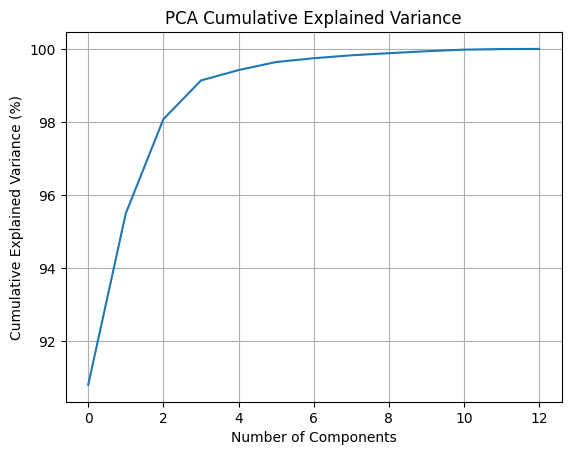

In [14]:
# TODO: Mean-center the data, apply PCA, and extract the principal components.
# TODO: Calculate the percentage of variance explained by the first three components.
# Store these percentages in 'var_pc1', 'var_pc2', and 'var_pc3' (e.g., 90.5 for 90.5%).
# TODO: Plot the Cumulative Explained Variance.

var_pc1 = 0.0 
var_pc2 = 0.0 
var_pc3 = 0.0

# mean-center
Xc = X - X.mean(axis=0, keepdims=True)

# PCA + principal components (scores)
pca = PCA()
PCs = pca.fit_transform(Xc)
print(PCs.shape)

# variance explained (%) for first 3 PCs
explained_pct = pca.explained_variance_ratio_ * 100
print(explained_pct)
var_pc1, var_pc2, var_pc3 = explained_pct[:3]

print(f"PC1: {var_pc1:.2f}%  PC2: {var_pc2:.2f}%  PC3: {var_pc3:.2f}%")

# cumulative explained variance plot
cum_explained = np.cumsum(explained_pct)
plt.figure()
plt.plot(cum_explained)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.grid()
plt.show()



### 4. Physical Interpretability
Let's calculate three physical metrics from our flattened original data `X`:
* `Brightness` = Mean of Visible + NIR bands (B2, B3, B4, B8)
* `NDVI` = (B8 - B4) / (B8 + B4)
* `NDWI` = (B3 - B8) / (B3 + B8)

*(Note: Sentinel-2 array indices: B2=1, B3=2, B4=3, B8=7)*


In [15]:
# TODO: Calculate Brightness, NDVI, and NDWI using the specified bands.
# TODO: Implement Min-Max scaling to normalize your 3 handcrafted indices AND the first 3 Principal Components to a [0, 1] range.

B2 = X[:, 1]
B3 = X[:, 2]
B4 = X[:, 3]
B8 = X[:, 7]



Brightness = (B2 + B3 + B4 + B8) / 4.0
eps = 1e-8
NDVI = (B8 - B4) / (B8 + B4+eps)
NDWI = (B3 - B8) / (B3 + B8+eps)

def minmax_scale(v):
    vmin, vmax = np.nanmin(v), np.nanmax(v)
    if np.isclose(vmax - vmin, 0):
        return np.zeros_like(v)
    return (v - vmin) / (vmax - vmin)
    
normalized_brightness=minmax_scale(Brightness)
normalized_NDVI = minmax_scale(NDVI)
normalized_NDWI = minmax_scale(NDWI)

PC1_n=minmax_scale(PCs[:,0])
PC2_n=minmax_scale(PCs[:,1])
PC3_n=minmax_scale(PCs[:,2])

print(Brightness.shape, NDVI.shape, NDWI.shape) 



(269361,) (269361,) (269361,)


### 5. Evaluating the Math (L1 Loss)
Calculate the Mean Absolute Error (L1 Loss) to see how closely the abstract Principal Components match the physical equations.
* Compare PC1 vs Brightness
* Compare PC2 vs NDVI
* Compare PC3 vs NDWI

**Advisory:** The mathematical direction (sign) of a Principal Component eigenvector is arbitrary. Be mindful of inversely related data before calculating your error.


In [16]:
def calc_l1_loss(true_arr, pred_arr):
    return np.mean(np.abs(true_arr - pred_arr))

# TODO: Calculate the L1 loss between the physical indices and their corresponding PCs. 
# Store the results in 'loss_pc1_bright', 'loss_pc2_ndvi', and 'loss_pc3_ndwi'

def align(pc, ref):
    if np.corrcoef(pc, ref)[0, 1] < 0:
        pc = 1 - pc
    return pc

PC1_n=align(PC1_n,normalized_brightness)
PC2_n=align(PC2_n,normalized_NDVI)
PC3_n=align(PC3_n,normalized_NDWI)

loss_pc1_bright = calc_l1_loss(PC1_n, normalized_brightness)
loss_pc2_ndvi = calc_l1_loss(PC2_n, normalized_NDVI)
loss_pc3_ndwi = calc_l1_loss(PC3_n, normalized_NDWI)


print(f"L1 Loss (PC1 vs Brightness): {loss_pc1_bright:.2f}")
print(f"L1 Loss (PC2 vs NDVI): {loss_pc2_ndvi:.2f}")
print(f"L1 Loss (PC3 vs NDWI): {loss_pc3_ndwi:.2f}")


L1 Loss (PC1 vs Brightness): 0.02
L1 Loss (PC2 vs NDVI): 0.14
L1 Loss (PC3 vs NDWI): 0.11


### 6. Analysis Questions

**Question 1:** Based on your Cumulative Variance calculations, what is the minimum number of Principal Components required to retain $\ge 95\%$ of the total variance in this dataset? 
*(You will add your integer answer to the final submission dictionary under the key `ans1`)*

**Question 2:** Analyze your L1 Loss results. Which PCs aligned well with known physical features, and which did not? Based on the properties of this dataset (a Level-1C image over an urban area), formulate a hypothesis explaining the physical meaning of the third principal component (PC3) and what PCA is isolating in this lower-variance component.
*(You will add your written analysis to the final submission dictionary under the key `ans2`)*


### 7. Submission Cell
Run this cell to generate your final submission payload.


In [17]:
import json

submission_data = {
    "ids": [9220302], #"your_student_id_here"
    "max_corr": round(float(max_corr), 2),
    "min_corr": round(float(min_corr), 2),
    "var_pc1": round(float(var_pc1), 2),
    "var_pc2": round(float(var_pc2), 2),
    "var_pc3": round(float(var_pc3), 2),
    "loss_pc1_bright": round(float(loss_pc1_bright), 2),
    "loss_pc2_ndvi": round(float(loss_pc2_ndvi), 2),
    "loss_pc3_ndwi": round(float(loss_pc3_ndwi), 2),
    "ans1":int(np.argmax(cum_explained >= 95) + 1),
    "ans2":
    '''PC1 aligned best as its L1 loss vs brightness is very low (0.02),
    PC2 aligns well with the NDVI this suggests that PC2 captures vegetation contrast but it is likely mixed with other urban materials,
    PC3 shows a moderate-to-good alignment with NDWI (low L1 loss), suggesting PC3 captures a moisture/water-shadow related contrast.
    Because this is Level-1C (top-of-atmosphere), 
    PC3 may still include atmospheric/haze-related variability mixed into this lower-variance component rather than being a purely water-only signal.
    ''',
    "notes": [
        '''Bonus Solution:
        2. Sentinel-2 L1C has 13 bands in this fixed order:
           Index 0  1  2  3  4  5  6  7  8   9  10  11  12
           Band  B1 B2 B3 B4 B5 B6 B7 B8 B8A B9 B10 B11 B12
           
           When going to L2A, B10 (Cirrus) is removed. 
           Since B10 sits at index 10 — which is after B8 at index 7 — 
           removing it only shifts B11 and B12, while everything from B1 through B8A stays in place.
           So no re-indexing is needed for the calculations of Brightness, NDVI, and NDWI when switching from L1C to L2A.
           
        3. Metric                    L1C (hazy) L2A (ground truth)
           PC1 Variance              90.81%     88.64%
           PC2 Variance              4.69%      5.09%
           PC3 Variance              2.58%      4.08%
           Min PCs for ≥95%          2          3
           L1 Loss PC1 vs Brightness 0.02       0.03
           L1 Loss PC2 vs NDVI       0.14       0.16
           L1 Loss PC3 vs NDWI       0.11       0.26
           
           Analysis:
           a. PC1 still captures brightness/albedo well in both images (low L1 loss), as expected since it dominates variance.
           b. PC3's L1 loss against NDWI jumps from 0.11 → 0.26 after atmospheric correction. 
              This strongly suggests that in the L1C image, PC3 was partly picking up atmospheric haze and cirrus effects
              — noise that happened to correlate with NDWI's water-sensitive signal. 
              Once that noise is removed, PC3 no longer tracks NDWI as closely, 
              meaning the haze was artificially inflating the alignment.
           c. PC3's variance share increases from 2.58% → 4.08% in the L2A image.
              Without the dominant haze signal, PCA redistributes variance more evenly, 
              and PC3 now captures real surface variability rather than atmospheric artifacts.
           d. We now need 3 PCs (instead of 2) to reach ≥95% variance in the L2A image, 
              according to point [c],
              "Removing atmospheric haze (B10) distributes variance more evenly across real surface features", 
              so one additional PC is needed to reach ≥95% cumulative variance.
        '''
    ], # For any additional comments or observations you have about the results can go here
    "msgs": [] # For any messages you want to convey to the TAs  
}

print("AUTOGRADER_OUTPUT_START")
print(json.dumps(submission_data, indent=4))
print("AUTOGRADER_OUTPUT_END")


AUTOGRADER_OUTPUT_START
{
    "ids": [
        9220302
    ],
    "max_corr": 0.99,
    "min_corr": 0.55,
    "var_pc1": 90.81,
    "var_pc2": 4.69,
    "var_pc3": 2.58,
    "loss_pc1_bright": 0.02,
    "loss_pc2_ndvi": 0.14,
    "loss_pc3_ndwi": 0.11,
    "ans1": 2,
    "ans2": "PC1 aligned best as its L1 loss vs brightness is very low (0.02),\n    PC2 aligns well with the NDVI this suggests that PC2 captures vegetation contrast but it is likely mixed with other urban materials,\n    PC3 shows a moderate-to-good alignment with NDWI (low L1 loss), suggesting PC3 captures a moisture/water-shadow related contrast.\n    Because this is Level-1C (top-of-atmosphere), \n    PC3 may still include atmospheric/haze-related variability mixed into this lower-variance component rather than being a purely water-only signal.\n    ",
    "notes": [
        "Bonus Solution:\n        2. Sentinel-2 L1C has 13 bands in this fixed order:\n           Index 0  1  2  3  4  5  6  7  8   9  10  11  12\n       

### 8. Bonus Challenge: Ground Truth Comparison (Level-2A)
You have just analyzed `hazy_cufe.tiff`, which is a Level-1C (Top of Atmosphere) image containing 13 bands, including the B10 Cirrus band which is highly sensitive to atmospheric noise and haze.

Provided in your data folder is another image: `gt_cufe.tiff`. This is a Level-2A (Surface Reflectance) "Ground Truth" image that has been atmospherically corrected. 
* **Note:** The Level-2A image only has **12 bands** because the B10 Cirrus band is removed after atmospheric correction.

**The Challenge:**
1. Change the `image_path` in Cell 3 to `"gt_cufe.tiff"` and rerun the entire notebook. 
2. *Advisory:* Double-check your array indices for calculating Brightness, NDVI, and NDWI. Since the Level-2A image dropped a band, did the column indices for B2, B3, B4, and B8 shift, or did the dropped band come later in the sequence?
3. **Analyze the differences:** How does the removal of atmospheric haze and the B10 band affect the Variance Explained by the Principal Components? Specifically, look at PC3. What does PC3 represent now that the atmospheric noise is gone? Does its L1 loss against physical indices improve?

*If you complete this challenge, add your comparative analysis as a string inside the `"notes"` list in your final submission dictionary!*
